# Demo: explainable AI for encrypted-traffic intrusion detection

A short walk-through of the project (CS3001 Computer Networks, Ahmed Raza and Huzaifa Mudassar).

1. Load the data and see what the three visibility tiers hide.
2. Train a detector on the encrypted-traffic view ($T_3$).
3. Explain one alert with a fast explainer (TreeSHAP) and a slow one (KernelSHAP).
4. Show the saved results of the full experiments: cost, quality, network change, the selective trigger and the known-answer check.

Steps 1–3 need the processed datasets in `data/processed/` (see `README.md`); if they are missing, those cells only print a note.
The full experiments take hours of single-core timing and are run with the numbered scripts in `scripts/`, not in this notebook.

In [1]:
import sys, json, time
from pathlib import Path

CODE = Path.cwd() if (Path.cwd() / "xaiids").exists() else Path.cwd() / "code"
sys.path.insert(0, str(CODE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from xaiids import data, models, explainers, metrics
from xaiids.config import DATA_PROC, RESULTS, FIGURES, SEED
from xaiids.tiers import tier_columns

pd.set_option("display.precision", 3)
DATA_OK = (DATA_PROC / "cic2017.parquet").exists()
print("processed data available:", DATA_OK)

processed data available: True


C:\Users\HP\Desktop\5th-Semester\Cnet\Project\Iteration_3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data and the three visibility tiers

* $T_1$: all flow features.
* $T_2$ (TLS 1.3): ports and protocol removed.
* $T_3$ (QUIC): all TCP-header features removed too, so only packet sizes, timing and direction remain.

In [2]:
if DATA_OK:
    df = data.load_processed("cic2017")
    all_feats = [c for c in df.columns if c not in data.META]
    tiers = {t: tier_columns(all_feats, t) for t in ("T1", "T2", "T3")}
    print("flows per split:", df.split.value_counts().to_dict())
    print("attack share in the test split: %.1f%%" % (100 * df[df.split == "test"].label.mean()))
    print("features per tier:", {t: len(c) for t, c in tiers.items()})
    print("examples of features removed by T3:", sorted(set(tiers["T1"]) - set(tiers["T3"]))[:8])
else:
    print(json.loads((RESULTS / "data_summary_cic2017.json").read_text())["split_rows"])

flows per split: {'train': 238850, 'test': 79593, 'val': 79533}
attack share in the test split: 50.0%
features per tier: {'T1': 84, 'T2': 79, 'T3': 59}
examples of features removed by T3: ['ACK Flag Count', 'Bwd Header Length', 'Bwd Init Win Bytes', 'Bwd PSH Flags', 'Bwd RST Flags', 'Bwd URG Flags', 'CWR Flag Count', 'Dst Port']


## 2. Train a detector on the encrypted-traffic view ($T_3$)

XGBoost with the report's settings; the alert threshold allows at most 1% false positives on validation data.
The notebook loads the trained detector used in the report (`results/models/cic2017_T3_XGB.joblib`). If that file is missing it retrains the model, which can give slightly different numbers because training uses several CPU threads.

In [3]:
if DATA_OK:
    cols = tiers["T3"]
    tr, va, te = (df[df.split == s] for s in ("train", "val", "test"))
    Xtr, Xte = tr[cols].to_numpy(np.float32), te[cols].to_numpy(np.float32)
    if (RESULTS / "models" / "cic2017_T3_XGB.joblib").exists():
        det = models.load("cic2017", "T3", "XGB")
        tau = json.loads((RESULTS / "thresholds.json").read_text())["cic2017|T3|XGB"]
        print("loaded the trained detector used in the report")
    else:
        t0 = time.time()
        det = models.make("XGB")
        det.fit(Xtr, tr.label.values, w=models.class_weights(tr.label.values))
        tau = metrics.threshold_for_fpr(va.label.values, det.predict_proba(va[cols].to_numpy(np.float32)), 0.01)
        print(f"retrained in {time.time() - t0:.0f} s")
    p = det.predict_proba(Xte)
    res = metrics.detection_metrics(te.label.values, p, tau)
    print({k: round(float(res[k]), 3) for k in ("precision", "recall", "f1", "fpr")})

loaded the trained detector used in the report


{'precision': 0.993, 'recall': 0.969, 'f1': 0.981, 'fpr': 0.007}


In [4]:
saved = pd.read_csv(RESULTS / "detection.csv")
saved[(saved.dataset == "cic2017") & (saved.model == "XGB")][["tier", "precision", "recall", "f1", "fpr", "roc_auc"]]

,tier,precision,recall,f1,fpr,roc_auc
15,T1,0.994,0.999,0.996,0.006,1.000
19,T2,0.993,0.996,0.994,0.007,1.000
23,T3,0.993,0.969,0.981,0.007,0.998


## 3. Explain one alert

TreeSHAP is exact and built for tree models; KernelSHAP works for any model but needs many model calls.
The times below are only an illustration: the report's timings come from isolated runs on one pinned CPU core.

TreeSHAP-path: 2.1 ms
KernelSHAP-500: 104.1 ms


,TreeSHAP-path,KernelSHAP-500
Bwd Packet Length Max,1.258,0.111
Bwd Packet Length Min,1.113,0.102
Packet Length Max,0.771,0.033
Subflow Fwd Bytes,-0.743,-0.007
Bwd Packets/s,0.630,0.037
Packet Length Min,0.523,0.031
Flow Duration,0.502,0.033
Bwd Packet Length Std,0.473,0.028


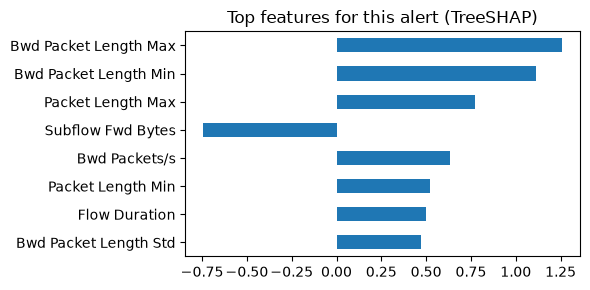

In [5]:
if DATA_OK:
    det.est.set_params(n_jobs=1)
    i = int(np.flatnonzero((te.label.values == 1) & (p >= tau))[0])      # first correctly flagged attack
    x = Xte[i]
    bg = explainers.background_kmeans(Xtr, 50, seed=SEED)
    out = {}
    for ex in (explainers.TreeSHAP(det, bg, "path"), explainers.KernelSHAP(det, bg, 500)):
        t0 = time.perf_counter()
        out[ex.label] = ex.explain(x)
        print(f"{ex.label}: {1000 * (time.perf_counter() - t0):.1f} ms")
    top = pd.DataFrame(out, index=cols)
    top = top.reindex(top["TreeSHAP-path"].abs().sort_values(ascending=False).index).head(8)
    display(top)
    top["TreeSHAP-path"][::-1].plot.barh(figsize=(6, 3), title="Top features for this alert (TreeSHAP)")
    plt.tight_layout(); plt.show()

## 4. Saved results of the full experiments

### Cost and quality of every explainer (CIC-IDS2017, $T_3$)
Median time per explanation on one CPU core, faithfulness (higher is better) and infidelity (lower is better).

In [6]:
def label(m, b):
    return m if b is None or b == "None" or (isinstance(b, float) and np.isnan(b)) else f"{m}-{int(float(b))}"

e1 = pd.DataFrame([json.loads(f.read_text()) for f in (RESULTS / "e1_isolated").glob("*.json")])
e1 = e1[(e1.dataset == "cic2017") & (e1.tier == "T3")].assign(explainer=lambda d: [label(m, b) for m, b in zip(d.method, d.budget)])
fid = pd.read_csv(RESULTS / "e2_fidelity.csv")
fid = fid[(fid.dataset == "cic2017") & (fid.tier == "T3")].assign(explainer=lambda d: [label(m, b) for m, b in zip(d.method, d.budget)])
tab = e1[["model", "explainer", "p50_ms"]].merge(fid[["model", "explainer", "faith_median", "infid_norm"]], on=["model", "explainer"])
tab.columns = ["Model", "Explainer", "Median ms", "Faithfulness", "Infidelity"]
tab.sort_values(["Model", "Median ms"]).reset_index(drop=True)

,Model,Explainer,Median ms,Faithfulness,Infidelity
0,EBM,EBM-native,0.329,0.470,0.751
1,EBM,KernelSHAP-500,30.410,0.336,0.844
2,LR,LinearSHAP,0.006,0.442,0.800
3,LR,LIME-1000,23.188,0.387,0.828
4,LR,KernelSHAP-500,44.899,0.460,0.705
5,MLP,IG-16,1.132,0.564,0.620
6,MLP,DeepSHAP,1.563,0.302,0.852
7,MLP,IG-32,1.616,0.556,0.604
8,MLP,IG-64,2.890,0.555,0.618
9,MLP,KernelSHAP-100,7.177,0.050,0.985


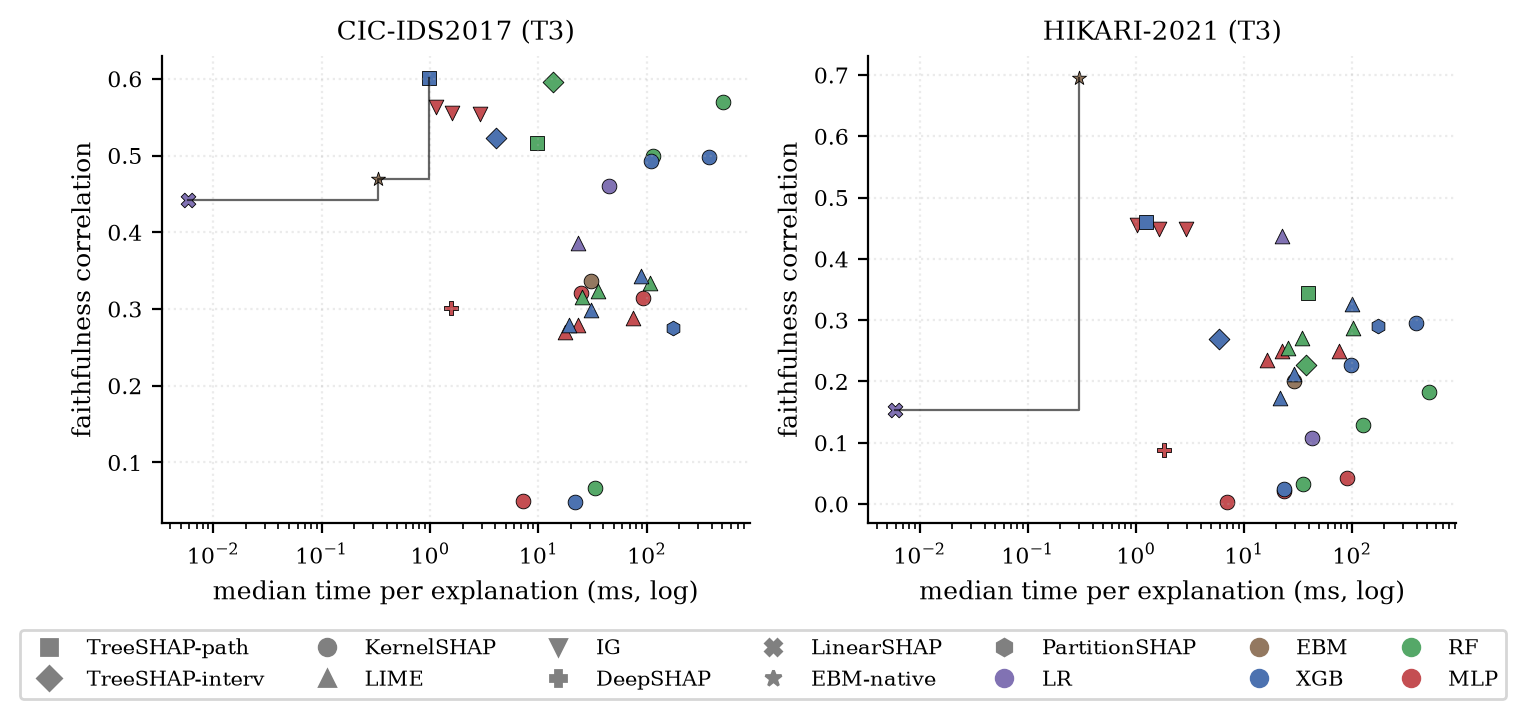

In [7]:
display(Image(str(FIGURES / "fig_cost_fidelity_pareto.png"), width=800))

### Does encryption hurt explanation quality?
Faithfulness on the same flows with all features ($T_1$) and with the encrypted-traffic view ($T_3$). On CIC-IDS2017 it goes **up** for 7 of 8 pairs.

In [8]:
t = pd.read_csv(RESULTS / "stats_tier_wilcoxon.csv")
t[t.dataset == "cic2017"][["model", "explainer", "faith_T1", "faith_T3", "p_holm"]].reset_index(drop=True)

,model,explainer,faith_T1,faith_T3,p_holm
0,MLP,DeepSHAP,0.235,0.302,7.261e-04
1,MLP,IG-32,0.466,0.556,3.393e-07
2,MLP,KernelSHAP-500,0.288,0.321,2.166e-01
3,MLP,LIME-1000,0.223,0.279,4.454e-03
4,XGB,KernelSHAP-500,0.290,0.493,2.132e-14
5,XGB,LIME-1000,0.232,0.299,1.918e-04
6,XGB,TreeSHAP-interv,0.352,0.522,1.266e-14
7,XGB,TreeSHAP-path,0.518,0.602,3.000e-05


### Explanations when the network changes (CIC-IDS2017 vs. CSE-CIC-IDS2018)

explanation drift vs. recall drop: Spearman rho = 0.63 (p = 0.008, n = 16)


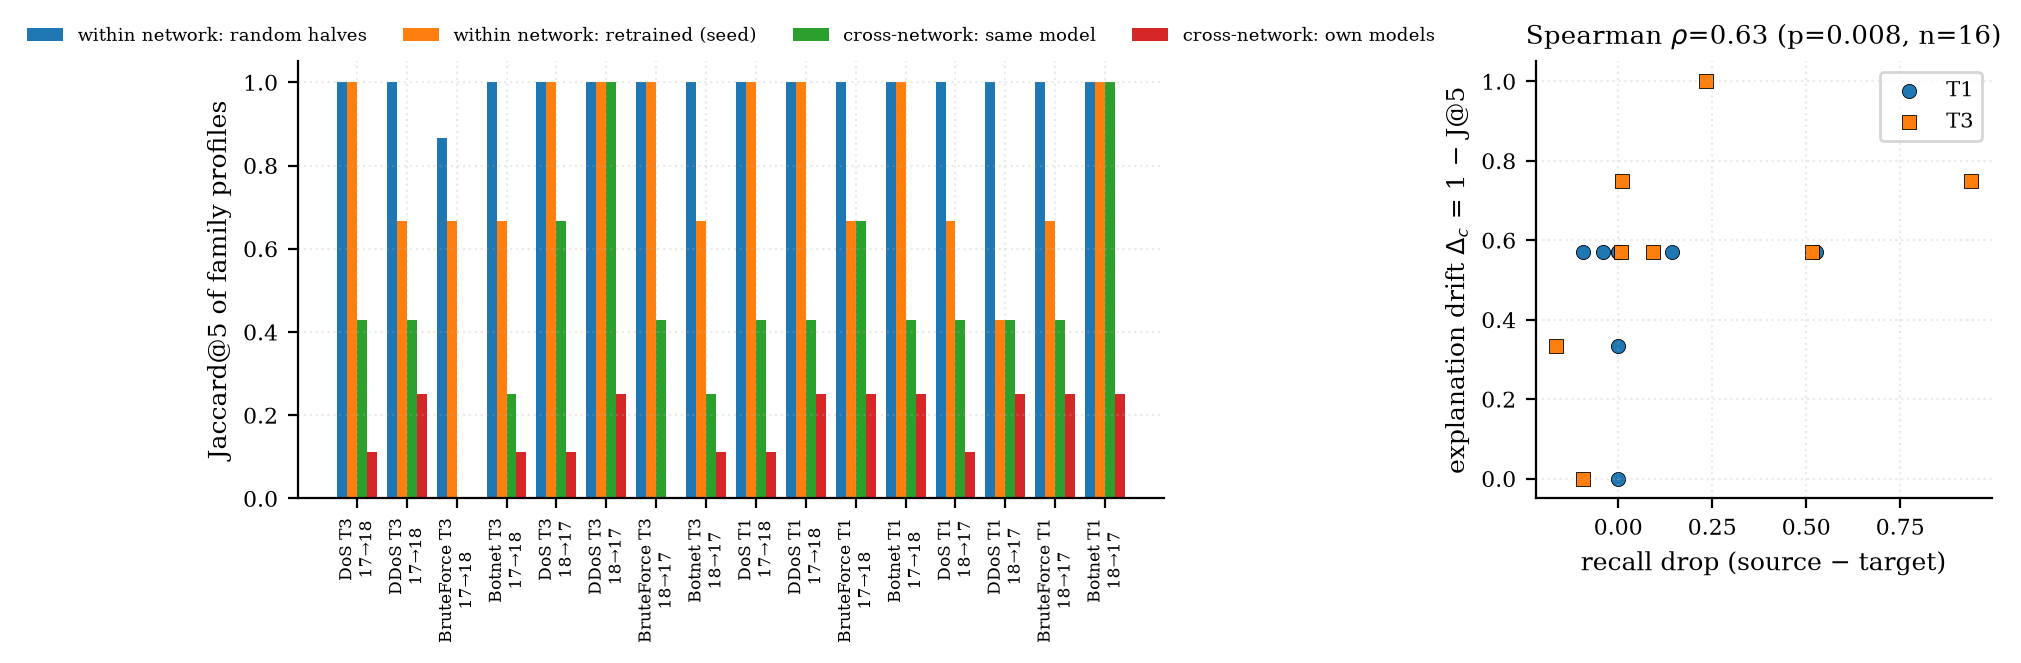

In [9]:
c = json.loads((RESULTS / "e3_crossnet_corr.json").read_text())
print(f"explanation drift vs. recall drop: Spearman rho = {c['spearman_drift_vs_recall_drop']:.2f} (p = {c['p']:.3f}, n = {c['n']})")
display(Image(str(FIGURES / "fig_drift.png"), width=850))

### The selective trigger under live traffic (CIC-IDS2017, 75% load)
Overhead = explanation work as a share of detection time; Covered = true alerts explained within 1 s; Delay = 99th-percentile verdict delay.

In [10]:
e4 = pd.read_csv(RESULTS / "e4_cic2017_XGB_T3.csv")
e4 = e4[(e4.load == 0.75) & (~e4.policy.str.startswith("A"))]
view = e4.pivot_table(index="policy", columns="scenario",
                      values=["O_xai_sync", "coverage_fast_incl_deferred@1s", "verdict_latency_p99_ms"])
view.columns = [f"{'Overhead' if a == 'O_xai_sync' else 'Covered' if a.startswith('coverage') else 'Delay ms'} ({s})" for a, s in view.columns]
view

,Overhead (burst),Overhead (mixed),Covered (burst),Covered (mixed),Delay ms (burst),Delay ms (mixed)
policy,,,,,,
B1 Explain-none,0.004,0.004,0.000,0.000,6.253e+00,3.186e+00
B2a Explain-all (fast),2.152,2.144,0.015,0.059,1.868e+04,1.672e+04
B2b Explain-all (deep),242.336,257.674,0.000,0.000,2.435e+06,2.117e+06
B3 Static global,0.004,0.004,0.000,0.000,3.916e+00,5.805e+01
B4 Random (matched rate),0.604,0.371,0.029,0.165,2.581e+03,2.427e+02
B5 Alert-only,0.418,0.131,0.413,1.000,2.676e+03,8.308e+00
B6 Amortised (all flows),0.289,0.288,1.000,0.746,6.705e+02,1.444e+03
Proposed,0.105,0.106,1.000,1.000,3.452e+01,3.191e+01


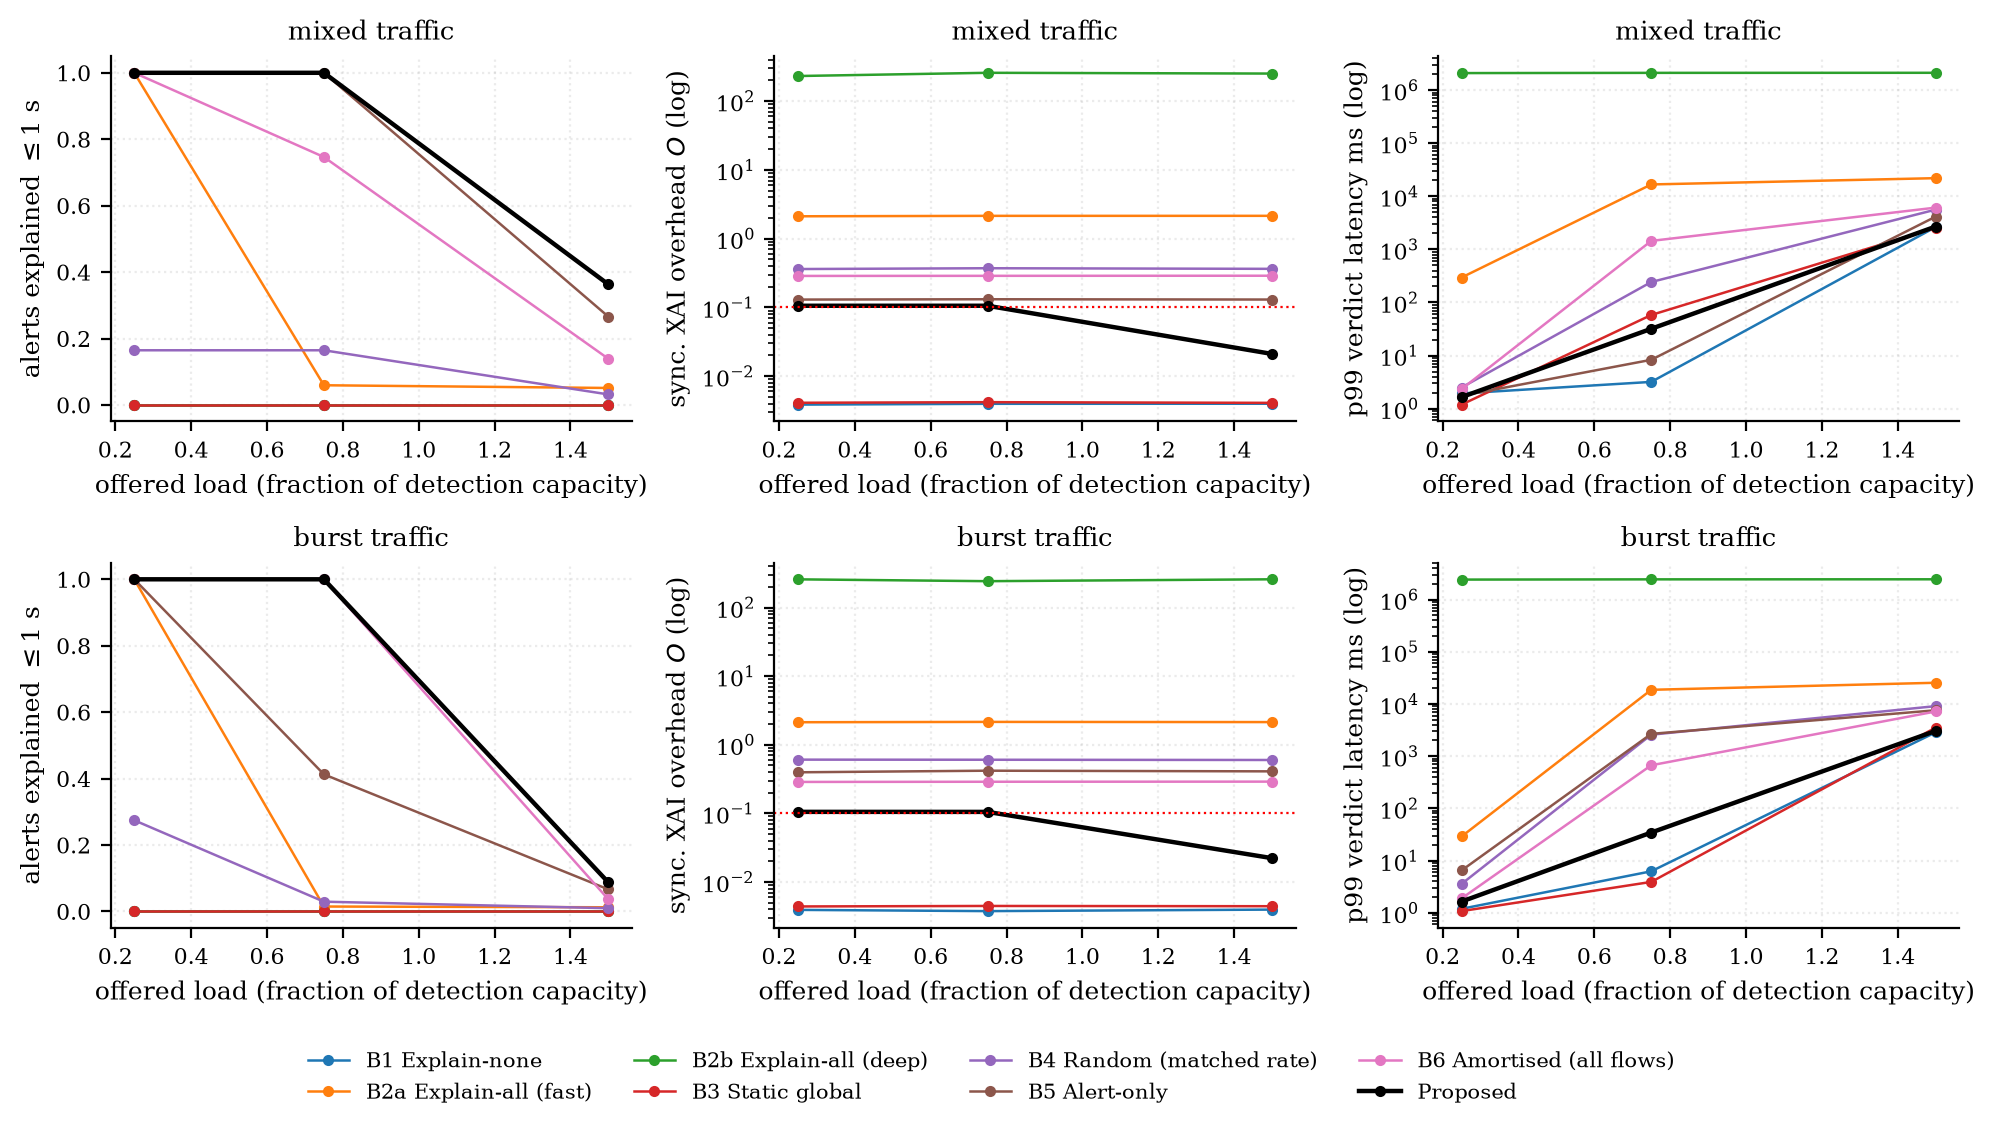

In [11]:
display(Image(str(FIGURES / "fig_stream_cic2017_XGB_T3.png"), width=900))

### Known-answer check
A planted feature is the true reason for some alerts and irrelevant for real attacks.
`hit_top1_A` = how often the explainer ranks it first when it is the reason (should be 1);
`false_top1_B` = how often it wrongly ranks it first for real attacks (should be 0).

In [12]:
pd.read_csv(RESULTS / "sanity_planted.csv")[["model", "explainer", "hit_top1_A", "mass_share_A", "false_top1_B"]]

,model,explainer,hit_top1_A,mass_share_A,false_top1_B
0,XGB,TreeSHAP-path,1.00,0.662,0.01
1,XGB,TreeSHAP-interv,1.00,0.752,0.00
2,XGB,KernelSHAP-100,0.85,0.300,0.02
3,XGB,KernelSHAP-500,1.00,0.795,0.00
4,XGB,LIME-1000,1.00,0.269,0.88
5,XGB,PartitionSHAP-500,1.00,0.884,0.00
6,MLP,IG-16,0.99,0.581,0.16
7,MLP,DeepSHAP,0.00,0.032,0.00
8,MLP,KernelSHAP-100,0.47,0.085,0.01
9,MLP,KernelSHAP-500,1.00,0.375,0.05


## Reproducing everything

Run from this folder (`code/`), in order; each script writes its results to `results/`:

```
python scripts/01_prepare_data.py hikari cic2017 cic2018
python scripts/02_train_models.py hikari cic2017
bash scripts/run_isolated.sh          # timing experiments, one at a time on an idle machine
python scripts/04_e2_fidelity.py
python scripts/05_e3_drift.py crossnet temporal hikari cic2017 p9
python scripts/09_figures.py && python scripts/11_tables.py
```

The complete list of commands is in `README.md`.